# Guide: choosing the mesh size

Convergence studies for the page *User guide → Choosing the mesh size*. The solver is called as in production.

1. **Resolution along a dipole** (structured mesh): half-wave strip at 300 MHz (0.47 m × 10 mm), the gap fixed (3 cells, 30 mm), the cell length elsewhere from λ/8 to λ/120. Input impedance from the enhanced gap source (`multiple_gap_sources`, as `radiation_algorithm` does).
2. **A wide strip** (40 mm, structured):
   - (a) cells across the width, 1 to 8, uniform or graded towards the edges, fed by a delta gap over the whole cut (`solver.optim` port), so that only the discretisation changes;
   - (b) the enhanced gap source with a gap of 30 mm (narrower than the strip) and 50 mm (wider): how many gap edges are fed, and the input impedance.
3. **Small features** (structured): a strip alone, and the same strip with a parallel strip 5 mm away (λ/60 at 1 GHz), the cell length along the strips from 17.5 mm to 1.1 mm. Input impedance of the feed port (`solver.optim` delta gap); the parasite is continuous metal.
4. **gmsh meshes**: the dipole of the first simulation (gap 50 mm) meshed by gmsh from λ/20 to λ/120, with the gap edges cutting through triangles (one rectangle) or aligned with mesh lines (the gap as its own surface); the structured strip as reference; local refinement around the feed with a `Ball` size field.

Nothing is written to `data/` (temporary folders only).

In [1]:
%matplotlib inline
import datetime, json, tempfile, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from fontTools.ttLib import TTFont
from matplotlib import font_manager

from solver.optim.geometries.planar import tensor_grid_mesh, grading_nodes, strip_dipole, parallel_strips
from solver.optim.reduced_model import ReducedMultiport
from solver.rwg.rwg3 import calculate_z_matrice
from solver.rwg.rwg4 import compute_port_results
from solver.utils.gap_source import multiple_gap_sources

OUT_DIR = Path("../source/figures/generated")
BLUE, AMBER, INK, GREY, GREEN = "#2563a6", "#e28a36", "#142b45", "#9aa5b1", "#3a9a7a"
font_cache = Path(tempfile.gettempdir()) / "antenna_solver_docs_fonts"
font_cache.mkdir(exist_ok=True)
for variant in ("400-normal", "400-italic", "700-normal"):
    ttf = font_cache / f"iosevka-{variant}.ttf"
    if not ttf.exists():
        font = TTFont(Path("../source/_static/fonts/iosevka") / f"iosevka-latin-{variant}.woff2")
        font.flavor = None
        font.save(ttf)
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams.update({"font.family": "Iosevka", "font.size": 11, "svg.fonttype": "path",
                     "mathtext.fontset": "custom", "mathtext.rm": "Iosevka",
                     "mathtext.it": "Iosevka:italic", "mathtext.bf": "Iosevka:bold"})

C0 = 1 / np.sqrt(8.854e-12 * 1.257e-6)
PROGRESS = Path(tempfile.gettempdir()) / "mom_docs_mesh_size_progress.log"
PROGRESS.write_text("", encoding="utf-8")
def log(msg):
    print(msg, flush=True)
    with PROGRESS.open("a", encoding="utf-8") as fh:
        fh.write(msg + "\n")

def half_line(a, b, h):
    """Grid lines from a to b with cells of about h (at least one)."""
    n = max(1, int(np.ceil((b - a) / h - 1e-9)))
    return np.linspace(a, b, n + 1)

def gap_strip(length, width, h_out, gap, n_gap=3, n_width=1, grading=None):
    """Strip along x centred at 0: the gap [-gap/2, gap/2] in n_gap cells, cells of about h_out elsewhere."""
    right = np.concatenate([np.linspace(0, gap / 2, n_gap // 2 + 1) if n_gap % 2 == 0 else
                            np.linspace(gap / (2 * n_gap), gap / 2, n_gap // 2 + 1),
                            half_line(gap / 2, length / 2, h_out)[1:]])
    xs = np.concatenate([-right[::-1], right]) if n_gap % 2 else np.concatenate([-right[:0:-1], right])
    xs = np.unique(np.round(xs, 12))
    ys = -width / 2 + width * grading_nodes(n_width, grading)
    return tensor_grid_mesh(xs, ys)

def z_in_gap(mesh, frequency, gap):
    """Input impedance with the enhanced gap source of radiation_algorithm; also the number of fed edges."""
    tri, edg = mesh.triangles, mesh.edges
    V, feeding = multiple_gap_sources(tri, edg, mesh.vecteurs_rho, 1.0, [[0, 0, 0]], "x", gap)
    t0 = time.perf_counter()
    *_, Z = calculate_z_matrice(mesh.points, tri, edg, frequency)
    I = np.linalg.solve(Z, V)
    dt = time.perf_counter() - t0
    port = compute_port_results(V, I, feeding, 1.0, [[0, 0, 0]], verbose=False)[0]
    return complex(port["impedance"]), dt, int(np.count_nonzero(V))

def z_in_port(mesh, frequency):
    """Input impedance of the 'feed' cut of a planar mesh (solver.optim delta gap over the whole cut)."""
    t0 = time.perf_counter()
    model = ReducedMultiport.from_mesh(mesh.points, mesh.triangles, mesh.edges, frequency, [mesh.port("feed")],
                                       keep_matrices=False)
    return complex(1.0 / model.Y[0, 0]), time.perf_counter() - t0

In [2]:
# 1. Resolution along a half-wave strip dipole (300 MHz, 0.47 m x 10 mm, gap 30 mm in 3 cells)
F1, LEN1, WID1, GAP1 = 300e6, 0.47, 0.010, 0.030
LAM1 = C0 / F1
RES1 = [8, 10, 15, 20, 30, 40, 60, 80, 120]
study1 = []
for r in RES1:
    m = gap_strip(LEN1, WID1, LAM1 / r, GAP1)
    z, dt, n_fed = z_in_gap(m, F1, GAP1)
    study1.append(dict(lambda_over_h=r, N=m.n_edges, R=z.real, X=z.imag, seconds=dt))
    log(f"study 1: lambda/{r}: N = {m.n_edges}, Z_in = {z:.2f} Ohm ({dt:.1f} s)")
z_ref1 = complex(study1[-1]["R"], study1[-1]["X"])
for row in study1:
    row["rel_err"] = abs(complex(row["R"], row["X"]) - z_ref1) / abs(z_ref1)

study 1: lambda/8: N = 13, Z_in = 68.07-6.15j Ohm (0.2 s)


study 1: lambda/10: N = 17, Z_in = 69.92-2.91j Ohm (0.4 s)


study 1: lambda/15: N = 21, Z_in = 70.69-1.59j Ohm (0.4 s)


study 1: lambda/20: N = 25, Z_in = 71.10-0.87j Ohm (0.5 s)


study 1: lambda/30: N = 33, Z_in = 71.53-0.08j Ohm (0.6 s)


study 1: lambda/40: N = 41, Z_in = 71.77+0.38j Ohm (0.9 s)


study 1: lambda/60: N = 61, Z_in = 72.05+0.98j Ohm (1.6 s)


study 1: lambda/80: N = 77, Z_in = 72.17+1.22j Ohm (3.2 s)


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (113x113 edges).


study 1: lambda/120: N = 113, Z_in = 72.30+1.48j Ohm (3.6 s)


In [3]:
# 2. A wide strip: 0.47 m x 40 mm at 300 MHz
WID2 = 0.040
N_WIDTH2 = [1, 2, 4, 8]

# (a) cells across the width, delta gap over the whole cut, ~lambda/120 along (56 cells)
study2a = []
for grading in (None, "cosine"):
    for n_w in (N_WIDTH2 if grading is None else N_WIDTH2[1:]):
        m = strip_dipole(LEN1, WID2, 56, n_w, edge_grading=grading)
        z, dt = z_in_port(m, F1)
        study2a.append(dict(n_width=n_w, grading=grading or "uniform", N=m.n_edges, R=z.real, X=z.imag, seconds=dt))
        log(f"study 2a: {grading or 'uniform'} x {n_w}: N = {m.n_edges}, Z_in = {z:.2f} Ohm ({dt:.1f} s)")

# (b) enhanced gap source: gap narrower (30 mm) and wider (50 mm) than the 40 mm strip, lambda/60 along
study2b = []
for gap in (0.030, 0.050):
    for n_w in N_WIDTH2:
        m = gap_strip(LEN1, WID2, LAM1 / 60, gap, n_width=n_w)
        z, dt, n_fed = z_in_gap(m, F1, gap)
        study2b.append(dict(gap_m=gap, n_width=n_w, N=m.n_edges, fed_edges=n_fed, R=z.real, X=z.imag))
        log(f"study 2b: gap {gap * 1e3:.0f} mm, {n_w} cells across: {n_fed} edges fed, Z_in = {z:.2f} Ohm")

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (111x111 edges).


study 2a: uniform x 1: N = 111, Z_in = 80.34+3.80j Ohm (2.2 s)


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (278x278 edges).


study 2a: uniform x 2: N = 278, Z_in = 82.93+8.01j Ohm (10.3 s)


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (612x612 edges).


study 2a: uniform x 4: N = 612, Z_in = 81.65+4.54j Ohm (15.6 s)


... (18 outputs left out)

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (315x315 edges).


study 2b: gap 50 mm, 4 cells across: 37 edges fed, Z_in = 79.19+14.19j Ohm


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (659x659 edges).


study 2b: gap 50 mm, 8 cells across: 77 edges fed, Z_in = 79.14+13.38j Ohm


In [4]:
# 3. A feature smaller than the cells: strip alone vs strip + parallel strip 5 mm away (1 GHz)
F3, LEN3, WID3, SPACING3 = 1e9, 0.140, 0.002, 0.005
N_LEN3 = [8, 12, 16, 24, 32, 48, 64, 96, 128]
study3 = {"alone": [], "with parasite": []}
for n in N_LEN3:
    for case, mesh in (("alone", strip_dipole(LEN3, WID3, n, 2)),
                       ("with parasite", parallel_strips(LEN3, WID3, SPACING3, n, 2))):
        z, dt = z_in_port(mesh, F3)
        study3[case].append(dict(n_len=n, h=LEN3 / n, h_over_spacing=LEN3 / n / SPACING3, N=mesh.n_edges,
                                 R=z.real, X=z.imag, seconds=dt))
        log(f"study 3 {case}: h = {LEN3 / n * 1e3:.2f} mm (h/s = {LEN3 / n / SPACING3:.2f}), N = {mesh.n_edges}, Z_in = {z:.2f} Ohm")
for case, rows in study3.items():
    zr = complex(rows[-1]["R"], rows[-1]["X"])
    for row in rows:
        row["rel_err"] = abs(complex(row["R"], row["X"]) - zr) / abs(zr)

study 3 alone: h = 17.50 mm (h/s = 3.50), N = 38, Z_in = 68.19-7.73j Ohm


study 3 with parasite: h = 17.50 mm (h/s = 3.50), N = 76, Z_in = 5.18-37.19j Ohm


study 3 alone: h = 11.67 mm (h/s = 2.33), N = 58, Z_in = 68.57-8.31j Ohm


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (116x116 edges).


study 3 with parasite: h = 11.67 mm (h/s = 2.33), N = 116, Z_in = 5.63-39.01j Ohm


study 3 alone: h = 8.75 mm (h/s = 1.75), N = 78, Z_in = 68.79-8.23j Ohm


... (22 outputs left out)

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (638x638 edges).


study 3 alone: h = 1.09 mm (h/s = 0.22), N = 638, Z_in = 69.69-5.99j Ohm


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (1276x1276 edges).


study 3 with parasite: h = 1.09 mm (h/s = 0.22), N = 1276, Z_in = 4.70-35.95j Ohm


In [5]:
# 4. gmsh meshes: are the edges of the gap mesh lines?
#    The dipole of the first simulation (0.47 m x 10 mm, 300 MHz, gap 50 mm = 0.05 wavelength),
#    solved with radiation_algorithm, on gmsh meshes of uniform size lambda/20 ... lambda/120:
#      - "not aligned": one rectangle, as usually drawn; the gap edges cut through triangles;
#      - "aligned": the gap cut out as its own surface (fragment), so its two edges are mesh lines;
#    and, as a reference, the structured strip (aligned by construction, 3 cells in the gap),
#    then local refinement with an aligned gap: a "Ball" size field around the feed.
#    radiation_algorithm integrates the gap field exactly over triangles cut by the gap (since the fix
#    of multiple_gap_sources); on the same meshes, the former one-point rule (multiple_gap_sources
#    without `points`) is also evaluated, for comparison.
import contextlib, io, os
import gmsh
from solver.rwg.rwg1 import DataManager_rwg1
from solver.rwg.rwg2 import DataManager_rwg2
from solver.rwg.rwg3 import DataManager_rwg3
from solver.utils.file_path import setup_save_file_paths
from solver.utils.gmsh_function import setup_performance_config, generate_and_save_mesh
from solver.src.radiation_algorithm.radiation_algorithm import radiation_algorithm

F4, LEN4, WID4 = 300e6, 0.47, 0.010
LAM4 = C0 / F4
GAP4 = 0.05 * LAM4
RES4 = [20, 30, 60, 120]
work4 = Path(tempfile.mkdtemp(prefix="mom_docs_mesh_gmsh_"))
here = Path.cwd()

def gmsh_dipole(name, size, aligned, fine_near_gap=None):
    path = setup_save_file_paths(name)
    with contextlib.redirect_stdout(io.StringIO()):
        gmsh.initialize()
        gmsh.option.setNumber("General.Terminal", 0)
        gmsh.model.add(name)
        setup_performance_config(n_threads=1)
        strip = gmsh.model.occ.addRectangle(-WID4 / 2, -LEN4 / 2, 0, WID4, LEN4)
        if aligned:
            # PAGE (mesh-size): the gap as its own surface, glued to the strip by fragment
            gap = gmsh.model.occ.addRectangle(-WID4 / 2, -GAP4 / 2, 0, WID4, GAP4)
            gmsh.model.occ.fragment([(2, strip)], [(2, gap)])
        gmsh.model.occ.synchronize()
        if fine_near_gap is not None:
            # PAGE (mesh-size): cells of fine_near_gap within one gap width of the feed, `size` elsewhere
            ball = gmsh.model.mesh.field.add("Ball")
            for key, value in (("XCenter", 0.0), ("YCenter", 0.0), ("ZCenter", 0.0), ("Radius", GAP4),
                               ("VIn", fine_near_gap), ("VOut", size)):
                gmsh.model.mesh.field.setNumber(ball, key, value)
            gmsh.model.mesh.field.setAsBackgroundMesh(ball)
        generate_and_save_mesh(path, size)
        gmsh.finalize()
        *_, impedances, _ = radiation_algorithm(path, F4, np.array([0.0, 0.0, 0.0]), excitation_unit_vector="y",
                                                gap_width=GAP4, show=False)
        # Former one-point rule on the same mesh and matrix, for comparison
        _, tri_, edg_, rho_ = DataManager_rwg2.load_data(path.mat_mesh2)
        *_, Zmat = DataManager_rwg3.load_data(path.mat_impedance)
        V_former, fed_former = multiple_gap_sources(tri_, edg_, rho_, 1.0, [[0, 0, 0]], "y", GAP4)
        I_former = np.linalg.solve(Zmat, V_former)
        z_former = compute_port_results(V_former, I_former, fed_former, 1.0, [[0, 0, 0]], verbose=False)[0]["impedance"]
    _, _, edges = DataManager_rwg1.load_data(path.mat_mesh1)
    return complex(np.atleast_1d(impedances)[0]), complex(z_former), int(edges.total_number_of_edges)

study4 = {"gmsh, not aligned": [], "gmsh, aligned": [], "structured": [], "gmsh, aligned, Ball refinement": []}
os.chdir(work4)
for res in RES4:
    for case, aligned in (("gmsh, not aligned", False), ("gmsh, aligned", True)):
        z, z_former, n_edges = gmsh_dipole(f"d{res}_{int(aligned)}", LAM4 / res, aligned)
        study4[case].append(dict(lambda_over_h=res, N=n_edges, R=z.real, X=z.imag,
                                 R_one_point_rule=z_former.real, X_one_point_rule=z_former.imag))
        log(f"study 4 {case}: lambda/{res}: N = {n_edges}, Z_in = {z:.2f} Ohm "
            f"(former one-point rule: {z_former:.2f} Ohm)")
for coarse_res, fine in ((10, GAP4 / 3), (20, GAP4 / 3), (20, GAP4 / 6)):
    z, z_former, n_edges = gmsh_dipole(f"ball{coarse_res}_{fine * 1e3:.0f}", LAM4 / coarse_res, True, fine)
    study4["gmsh, aligned, Ball refinement"].append(dict(lambda_over_h=coarse_res, fine_m=fine, N=n_edges,
                                                         R=z.real, X=z.imag))
    log(f"study 4 Ball: lambda/{coarse_res} + {fine * 1e3:.1f} mm near the feed: N = {n_edges}, Z_in = {z:.2f} Ohm")
os.chdir(here)
for res in RES4:
    m = gap_strip(LEN4, WID4, LAM4 / res, GAP4)
    z, dt, n_fed = z_in_gap(m, F4, GAP4)
    study4["structured"].append(dict(lambda_over_h=res, N=m.n_edges, R=z.real, X=z.imag))
    log(f"study 4 structured: lambda/{res}: N = {m.n_edges}, Z_in = {z:.2f} Ohm")

Directory created: data/gmsh_files/
Directory created: data/antennas_mesh/
Directory created: data/antennas_mesh1/
Directory created: data/antennas_mesh2/
Directory created: data/antennas_impedance/
Directory created: data/antennas_current/
Directory created: data/antennas_gain_power/
Directory created: data/antennas_sweep/


study 4 gmsh, not aligned: lambda/20: N = 19, Z_in = 71.41-1.87j Ohm (former one-point rule: 79.97-2.78j Ohm)


study 4 gmsh, aligned: lambda/20: N = 21, Z_in = 71.64-0.85j Ohm (former one-point rule: 71.64-0.85j Ohm)


study 4 gmsh, not aligned: lambda/30: N = 29, Z_in = 71.83-0.60j Ohm (former one-point rule: 181.76-2.69j Ohm)


study 4 gmsh, aligned: lambda/30: N = 37, Z_in = 71.90-0.32j Ohm (former one-point rule: 71.90-0.32j Ohm)


study 4 gmsh, not aligned: lambda/60: N = 144, Z_in = 72.73+4.08j Ohm (former one-point rule: 76.76+4.26j Ohm)


... (7 outputs left out)

study 4 structured: lambda/30: N = 33, Z_in = 71.97+0.60j Ohm


study 4 structured: lambda/60: N = 57, Z_in = 72.40+1.75j Ohm


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (109x109 edges).


study 4 structured: lambda/120: N = 109, Z_in = 72.66+2.36j Ohm


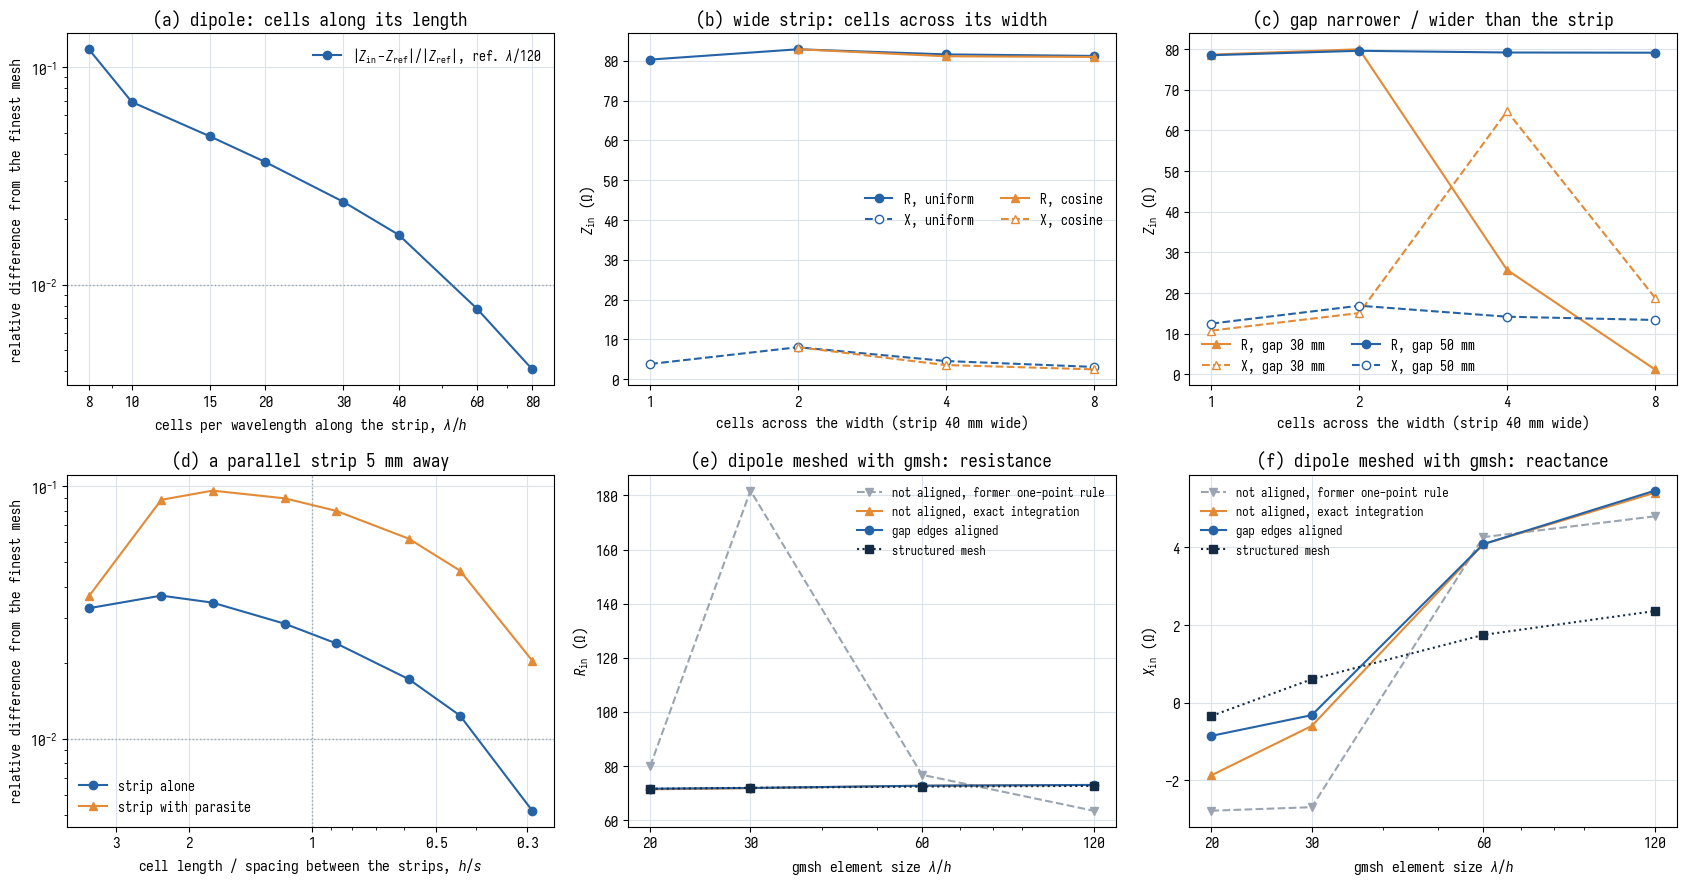

In [6]:
from matplotlib.ticker import NullFormatter

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
(ax1, ax2, ax3), (ax4, ax5, ax6) = axes

res = np.array([r["lambda_over_h"] for r in study1])
ax1.loglog(res[:-1], [r["rel_err"] for r in study1[:-1]], "-o", color=BLUE,
           label=r"$|Z_\mathrm{in} - Z_\mathrm{ref}| / |Z_\mathrm{ref}|$, ref. $\lambda/120$")
ax1.axhline(0.01, color=GREY, ls=":", lw=1)
ax1.set_xticks(res[:-1]); ax1.set_xticklabels([str(r) for r in res[:-1]])
ax1.set_xlabel(r"cells per wavelength along the strip, $\lambda/h$")
ax1.set_ylabel("relative difference from the finest mesh")
ax1.set_title("(a) dipole: cells along its length")
ax1.legend(frameon=False, fontsize=10)

for grading, color, marker in (("uniform", BLUE, "o"), ("cosine", AMBER, "^")):
    rows = [r for r in study2a if r["grading"] == grading]
    ax2.plot([r["n_width"] for r in rows], [r["R"] for r in rows], "-" + marker, color=color, label=f"R, {grading}")
    ax2.plot([r["n_width"] for r in rows], [r["X"] for r in rows], "--" + marker, color=color, mfc="white",
             label=f"X, {grading}")
ax2.set_xscale("log", base=2); ax2.set_xticks(N_WIDTH2); ax2.set_xticklabels([str(n) for n in N_WIDTH2])
ax2.set_xlabel("cells across the width (strip 40 mm wide)")
ax2.set_ylabel(r"$Z_\mathrm{in}$ ($\Omega$)")
ax2.set_title("(b) wide strip: cells across its width")
ax2.legend(frameon=False, fontsize=10, ncol=2)

for gap, color, marker in ((0.030, AMBER, "^"), (0.050, BLUE, "o")):
    rows = [r for r in study2b if r["gap_m"] == gap]
    ax3.plot([r["n_width"] for r in rows], [r["R"] for r in rows], "-" + marker, color=color,
             label=f"R, gap {gap * 1e3:.0f} mm")
    ax3.plot([r["n_width"] for r in rows], [r["X"] for r in rows], "--" + marker, color=color, mfc="white",
             label=f"X, gap {gap * 1e3:.0f} mm")
ax3.set_xscale("log", base=2); ax3.set_xticks(N_WIDTH2); ax3.set_xticklabels([str(n) for n in N_WIDTH2])
ax3.set_xlabel("cells across the width (strip 40 mm wide)")
ax3.set_ylabel(r"$Z_\mathrm{in}$ ($\Omega$)")
ax3.set_title("(c) gap narrower / wider than the strip")
ax3.legend(frameon=False, fontsize=10, ncol=2)

for case, color, marker in (("alone", BLUE, "o"), ("with parasite", AMBER, "^")):
    rows = study3[case][:-1]
    ax4.loglog([r["h_over_spacing"] for r in rows], [r["rel_err"] for r in rows], "-" + marker, color=color,
               label=f"strip {case}")
ax4.axvline(1.0, color=GREY, ls=":", lw=1)
ax4.axhline(0.01, color=GREY, ls=":", lw=1)
ax4.set_xticks([3, 2, 1, 0.5, 0.3]); ax4.set_xticklabels(["3", "2", "1", "0.5", "0.3"])
ax4.xaxis.set_minor_formatter(NullFormatter())
ax4.invert_xaxis()
ax4.set_xlabel("cell length / spacing between the strips, $h/s$")
ax4.set_ylabel("relative difference from the finest mesh")
ax4.set_title("(d) a parallel strip 5 mm away")
ax4.legend(frameon=False, fontsize=10)

series = (("gmsh, not aligned", "R_one_point_rule", "X_one_point_rule", GREY, "v", "--", "not aligned, former one-point rule"),
          ("gmsh, not aligned", "R", "X", AMBER, "^", "-", "not aligned, exact integration"),
          ("gmsh, aligned", "R", "X", BLUE, "o", "-", "gap edges aligned"),
          ("structured", "R", "X", INK, "s", ":", "structured mesh"))
for case, kr, kx, color, marker, ls, label in series:
    rows = study4[case]
    ax5.plot([r["lambda_over_h"] for r in rows], [r[kr] for r in rows], ls + marker, color=color, label=label)
    ax6.plot([r["lambda_over_h"] for r in rows], [r[kx] for r in rows], ls + marker, color=color, label=label)
for ax, what in ((ax5, "R"), (ax6, "X")):
    ax.set_xscale("log"); ax.set_xticks(RES4); ax.set_xticklabels([str(r) for r in RES4])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(r"gmsh element size $\lambda/h$")
    ax.set_ylabel(rf"${what}_\mathrm{{in}}$ ($\Omega$)")
    ax.legend(frameon=False, fontsize=9)
ax5.set_title("(e) dipole meshed with gmsh: resistance")
ax6.set_title("(f) dipole meshed with gmsh: reactance")
for ax in axes.flat:
    ax.grid(True, which="major", color="#dde3ea", lw=0.8)
fig.tight_layout()
fig.savefig(OUT_DIR / "mesh_size_convergence.svg", bbox_inches="tight", facecolor="white")
plt.show()

In [7]:
def git_commit(repo=Path("../..")):
    """Current commit, read from the git files directly (git may not be on the kernel's PATH).
    Works in a normal clone (.git is a folder) and in a worktree (.git is a file pointing to it)."""
    dot_git = repo / ".git"
    if dot_git.is_file():
        git_dir = Path(dot_git.read_text().split("gitdir:", 1)[1].strip())
        common = (git_dir / (git_dir / "commondir").read_text().strip()).resolve() \
            if (git_dir / "commondir").exists() else git_dir
    else:
        git_dir = common = dot_git
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]
    ref_file = common / head[5:]
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (common / "packed-refs").read_text().splitlines():
        if line.endswith(" " + head[5:]):
            return line.split()[0][:7]
    return "unknown"

provenance = {
    "figure": "mesh_size_convergence.svg",
    "notebook": "documentation/figure_notebooks/guide_mesh_size.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "study1": {"frequency_hz": F1, "length_m": LEN1, "width_m": WID1, "gap_m": GAP1, "rows": study1},
    "study2a": {"frequency_hz": F1, "length_m": LEN1, "width_m": WID2, "n_len": 56, "feed": "solver.optim port",
                "rows": study2a},
    "study2b": {"frequency_hz": F1, "length_m": LEN1, "width_m": WID2, "feed": "multiple_gap_sources",
                "rows": study2b},
    "study3": {"frequency_hz": F3, "length_m": LEN3, "width_m": WID3, "spacing_m": SPACING3, "rows": study3},
    "study4": {"frequency_hz": F4, "length_m": LEN4, "width_m": WID4, "gap_m": GAP4, "feed": "radiation_algorithm",
               "rows": study4},
}
(OUT_DIR / "mesh_size.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(json.dumps({k: provenance[k] for k in ("solver_commit", "generated")}))

{"solver_commit": "c87121a", "generated": "2026-11-19"}
